# Zeno-Clock Circuit Feasibility on Nighthawk and Heron

*Notebook by Claude (Opus 4.6), edited and checked by Sara Sussman and Olivia Seidel*

This notebook estimates whether the superposed-schedule Zeno circuit from
Seidel et al. (Fig. 1(b) of the paper) can run on IBM's two current
processor families, Nighthawk and Heron.

### Contents

We start with the physics and define what the circuit needs to do.

1. **Background.** The quantum Zeno effect and the superposed-schedule circuit.
2. **What this notebook computes.** The target is $N = 8$ Zeno measurements on 10 qubits, as shown in the paper.

We start comparing the Heron and Nighthawk processors for running this circuit.

3. **Setup and hardware parameters.** Coherence times, gate errors, and where the numbers come from.
4. **Processor topology.** Nighthawk qubits have up to 4 neighbors; Heron qubits have only 2 or 3. This connectivity gap drives most of what follows.

We build the circuit and compile it onto each chip with no circuit optimization. Nighthawk's extra connectivity means far fewer SWAP gates are needed to run the circuit: 48 CX gates at $N = 8$ versus 108 on Heron.

5. **Circuit construction.** The gate sequence from Fig. 1(b) of the paper.
6. **Two-qubit gate primitives.** Each controlled rotation costs 2 CX gates; each drive-and-record step costs 1.
7. **Ideal cost.** $N + 4$ CX gates if every qubit could sit next to $S$. This is the floor.
8. **Compilation at optimization level 0.** The actual gate counts after the compiler inserts SWAPs for each chip's wiring. Here, the SWAP overhead isn't reduced by any circuit optimization, we are just running the naive circuit as given in the paper. This takes more SWAPs than it would if we optimized the circuit, which we will discuss a bit more later. But for now, we will just use these conservative settings to make sure we are running a circuit that is identical to the paper.

The compiled circuit depths set the noise floor. At $N = 8$, Nighthawk keeps an estimated fidelity of 0.81; Heron has an estimated fidelity of 0.54.

9. **Fidelity budget.** Gate error and decoherence as a function of $N$, using $T_2^*$ (Ramsey) for a conservative estimate.

We then run the two experiments from the paper. Both are feasible on these processors.

10. **Experiment 1: Conditional system probabilities.** The complement relation $P_0^{(N,-)} = 1 - P_0^{(N)}$.
11. **Experiment 2: Memory parity.** The $X$-basis parity test, which is more sensitive to readout error and memory dephasing.
12. **A note on optimization levels.** Higher levels reduce SWAP overhead but cannot go below the $N + 4$ floor.
13. **Caveats.**

## 1. Background

### The quantum Zeno effect

The quantum Zeno effect occurs when frequent measurements freeze the
dynamics of a driven quantum system. A two-level system driven
continuously between its states will oscillate back and forth. If instead
it is measured many times during the drive, each measurement collapses it
back toward the starting state. As the number of measurements $N$ grows
at fixed total drive time $T$, the probability that the system remains in
its initial state approaches one.

### Superposed measurement schedules

Seidel et al. place two Zeno measurement schedules in quantum
superposition using a schedule qubit $Q$. The two schedules,
$\mathcal{A}$ and $\mathcal{B}$, each contain $N$ measurements separated
by $\Delta t = T/N$. They differ by a time offset $\delta$: schedule
$\mathcal{A}$ places the offset after the measurement train, schedule
$\mathcal{B}$ places it before. The schedule qubit, prepared in
$|+\rangle_Q$, runs both schedules simultaneously.

### The circuit

The circuit uses $N+2$ qubits: a system qubit $S$, a schedule qubit $Q$,
and $N$ memory qubits $M_1,\ldots,M_N$.

- **$S$** is the driven two-level system.
- **$Q$** controls which schedule runs.  Prepared in $|+\rangle_Q$ by an
  initial Hadamard gate, it places the two schedules in superposition.
- **$M_1,\ldots,M_N$** record the measurements.  Each memory starts in
  $|0\rangle$; a CX gate (controlled-NOT) from $S$ to $M_k$ copies the
  state of $S$ into $M_k$, entangling them and collapsing the coherence
  of $S$.

The gate sequence is:

1. Prepare $Q$ in $|+\rangle_Q$, $S$ in $|0\rangle$, all memories in
   $|0\rangle$.
2. Apply a controlled rotation $CR_x(\Omega\delta)$ on $S$, controlled
   on $Q$. This is the schedule-$\mathcal{B}$ delay.
3. Run the measurement train: for $k=1,\ldots,N$, apply a rotation
   $R_x(\Omega\Delta t)$ on $S$ then a CX gate from $S$ to $M_k$.
4. Apply the same controlled rotation with flipped control, so the
   delay occurs in the $\mathcal{A}$ branch instead.
5. Hadamard on $Q$, then measure $Q$ and $S$.

### What we test

**Experiment 1 — Conditional system probabilities.** The paper predicts
$P_0^{(N,-)} = 1 - P_0^{(N)}$: conditioned on the $|-\rangle_Q$
outcome, the probability of finding $S$ in $|0\rangle$ is the complement
of the standard Zeno probability. This is a precise, parameter-free
prediction.

**Experiment 2 — Memory parity.** Conditioned on $|-\rangle_Q$, the
joint $X$-basis parity of all $N$ memories is exactly $-1$. A classical
or dephased schedule gives zero. This tests whether the recorded
measurement outcomes retain coherence.

## 2. What this notebook computes

The target run is $N = 8$, $\Omega T = 3$, with $\Omega\delta$ swept
across $[0, \pi]$. This matches Fig. 1(b) of the paper. The circuit
uses $N + 2 = 10$ qubits.

The notebook answers three questions:

1. **Compiled gate count.** How many two-qubit gates (CX gates) does the
   circuit need on each chip after the compiler inserts the extra gates
   required by the chip's wiring?
2. **Gate-error fidelity.** At what circuit size does accumulated gate
   error become a problem?
3. **Decoherence fidelity.** How much additional fidelity is lost to
   qubit dephasing during the circuit?

Both experiments (conditional probabilities and memory parity) use the
same two-qubit gate structure. The only difference is $N$ single-qubit
Hadamard gates on the memories before readout in Experiment 2, which do
not change the two-qubit cost. So the feasibility analysis applies to
both.

In [1]:
# Install (uncomment first time on Colab)
!pip install qiskit pylatexenc matplotlib networkx --quiet

## 3. Setup and hardware parameters

We define the two processor families and their key performance numbers.
All values are round-number proxies for the medians across qubits, derived from IBM's public calibration data. Daily calibration
varies, and individual qubits can differ substantially from the median.

**How to verify these numbers yourself (Qiskit):**

```python
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()
backend = service.backend('ibm_fez')          # Heron r2
# Per-qubit coherence:
print(backend.properties().t2(0))              # T2 for qubit 0
# Per-edge gate error & duration:
print(backend.target['cz'][(0, 1)])            # CZ error & duration for edge (0,1)
```

**$T_2^*$ (Ramsey) versus $T_2$ (echo).**  IBM's calibration page reports
$T_2$ from an echo experiment, which corrects for low-frequency noise.
The echo value is typically 150–200 $\mu$s. But qubits that sit idle in
the circuit — with no correcting pulses applied — lose coherence at the
faster Ramsey rate $T_2^*$, which is roughly 5–6$\times$ shorter
(approximately 50 $\mu$s on Eagle-generation hardware). Since no
echo pulses act on any qubit during the Zeno circuit, $T_2^*$ is the
correct dephasing rate to use. IBM does not report $T_2^*$ in its
calibration data, so we adopt the value measured by Agrawal et al.
([arXiv:2603.03157](https://arxiv.org/abs/2603.03157)) on the
previous-generation Eagle processors. The true $T_2^*$ on Heron and
Nighthawk may differ, but 50 $\mu$s is a reasonable conservative
estimate until direct measurements are available.

**Sources for the specific values used:**

| Parameter | Heron r2 | Nighthawk r2 | Source |
|---|---|---|---|
| CZ gate time | 68 ns | 68 ns | IBM QPU information docs ([docs](https://quantum.cloud.ibm.com/docs/en/guides/qpu-information)) |
| Two-qubit gate error | ~4.3×10⁻³ | ~3.1×10⁻³ | [IBM Quantum Compute Resources dashboard](https://quantum.cloud.ibm.com/computers), accessed Oct 2026. This is the average CZ error when a full layer of simultaneous two-qubit gates runs across the chip. ibm_kingston = 4.252×10⁻³, ibm_phoenix (Nighthawk) = 3.144×10⁻³ |
| $T_1$ (median) | ~260 μs | ~350 μs | Heron: live median from ibm_kingston (Oct 2026). Nighthawk: [The Quantum Insider, Jan 2026](https://thequantuminsider.com/2026/01/13/ibm-announces-nighthawk-and-latest-heron-are-now-available/) |
| $T_2$ echo (median) | ~167 μs | ~200 μs | Echo $T_2$ from IBM calibration. Heron: live median from ibm_kingston (Oct 2026). Nighthawk: round-number proxy |
| $T_2^*$ Ramsey | ~50 μs | ~50 μs | IBM does not report $T_2^*$. We adopt ~50 μs from [arXiv:2603.03157](https://arxiv.org/abs/2603.03157), who measured $T_2^* \approx$ 34–52 μs on the previous-generation Eagle processors (ibm_sherbrooke, ibm_brisbane). See §9 |

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.transpiler import CouplingMap
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import math
import numpy as np
import networkx as nx

from collections import namedtuple

HWParams = namedtuple('HWParams', [
    'name',         # human-readable label
    'T1_us',        # T1 relaxation time (microseconds)
    'T2_echo_us',   # T2 Hahn echo (microseconds) -- IBM calibration value
    'T2_star_us',   # T2* Ramsey (microseconds) -- free-induction decay
    'cz_ns',        # CZ gate duration (nanoseconds)
    'cz_err',       # CZ gate error rate (EPLG)
])

HERON = HWParams(
    name='Heron r2',
    T1_us=260,            # live median from ibm_kingston, Oct 2026
    T2_echo_us=167,       # live median from ibm_kingston, Oct 2026
    T2_star_us=50,        # ~50 us -- arXiv:2603.03157
    cz_ns=68,
    cz_err=4.3e-3,        # EPLG from ibm_kingston, Oct 2026
)

NIGHTHAWK = HWParams(
    name='Nighthawk r2',
    T1_us=350,            # ~350 us (The Quantum Insider, Jan 2026)
    T2_echo_us=200,       # round-number proxy (no live data available)
    T2_star_us=50,        # ~50 us -- assumed comparable to Heron (arXiv:2603.03157)
    cz_ns=68,
    cz_err=3.1e-3,        # EPLG from ibm_phoenix, Oct 2026
)

for hw in [HERON, NIGHTHAWK]:
    print(f'{hw.name}:')
    print(f'  T1 = {hw.T1_us} us,  T2(echo) = {hw.T2_echo_us} us,  T2* = {hw.T2_star_us} us')
    print(f'  CZ time = {hw.cz_ns} ns,  EPLG = {hw.cz_err}')
    print()

Heron r2:
  T1 = 260 us,  T2(echo) = 167 us,  T2* = 50 us
  CZ time = 68 ns,  EPLG = 0.0043

Nighthawk r2:
  T1 = 350 us,  T2(echo) = 200 us,  T2* = 50 us
  CZ time = 68 ns,  EPLG = 0.0031



### Live $T_1$ / $T_2$ check (optional)

The coherence values above are round-number proxies. The cell below
queries the IBM backends directly and computes the median $T_1$ and $T_2$
across all qubits. **The code is commented out by default** so that
"Run all" works without credentials. To use it:

**Step 1 — Get an IBM Quantum account.**
Sign up at [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com/).
The free Open Plan gives access to several backends.

**Step 2 — Install the runtime package.**
```
pip install qiskit-ibm-runtime
```

**Step 3 — Save your API token** (once per machine).
```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(
    channel='ibm_quantum_platform',   # or 'ibm_cloud'
    token='YOUR_API_TOKEN',           # from your IBM Quantum dashboard
)
```

**Step 4 — Uncomment the code cell below and run it.** It will list
available backends, then pull the median $T_1$ and $T_2$ for each one.

> **Important:** IBM's `backend.properties().t2()` returns the **echo
> $T_2$**, not the Ramsey $T_2^*$.  For the Zeno circuit, where no echo
> pulses act on any qubit, $T_2^*$ (typically 5–6$\times$ shorter) is the
> relevant decoherence timescale. See §9 for details.

In [3]:
# -- Live T1 / T2 (echo) from IBM backends (optional) ---------
# To use: uncomment all lines below (select all, Ctrl+/ in Colab).
#
# Requires: pip install qiskit-ibm-runtime
# and credentials saved via:
#   from qiskit_ibm_runtime import QiskitRuntimeService
#   QiskitRuntimeService.save_account(
#       channel='ibm_quantum_platform',
#       token='YOUR_API_TOKEN',
#   )
#
# Note: backend.properties().t2() returns Hahn-echo T2, NOT Ramsey T2*.
# T2* (free-induction decay) is typically 5-6x shorter and is the
# relevant timescale for the Zeno circuit.  See section 9.

# from qiskit_ibm_runtime import QiskitRuntimeService
#
# # -- Step 1: connect ------------------------------------------
# service = QiskitRuntimeService()
#
# # -- Step 2: find Heron and Nighthawk backends ----------------
# # List what is available -- backend names vary by access plan.
# all_backends = service.backends(operational=True, min_num_qubits=50)
# print('Available backends (>=50 qubits):')
# for b in all_backends:
#     print(f'  {b.name:<20s}  {b.num_qubits} qubits')
#
# # -- Step 3: pull T1 and T2 -----------------------------------
# # Edit these names to match what Step 2 printed.
# backends_to_check = {
#     'Heron r2':     'ibm_kingston',    # or ibm_fez, ibm_marrakesh
#     'Nighthawk r2': 'ibm_phoenix',
# }
#
# for label, backend_name in backends_to_check.items():
#     try:
#         backend = service.backend(backend_name)
#     except Exception as e:
#         print(f'\nCould not access {backend_name}: {e}')
#         print(f'  Pick a name from the list above and edit backends_to_check.')
#         continue
#
#     props = backend.properties()
#     n_qubits = backend.num_qubits
#
#     t1_values, t2_values = [], []
#     for q in range(n_qubits):
#         try:
#             val = props.t1(q) * 1e6   # s -> us
#             if val > 0: t1_values.append(val)
#         except Exception:
#             pass
#         try:
#             val = props.t2(q) * 1e6
#             if val > 0: t2_values.append(val)
#         except Exception:
#             pass
#
#     t1_arr, t2_arr = np.array(t1_values), np.array(t2_values)
#     print(f'\n{label} ({backend_name}), {n_qubits} qubits:')
#     if len(t1_arr):
#         print(f'  T1: median = {np.median(t1_arr):.0f} us,  '
#               f'range {np.min(t1_arr):.0f}-{np.max(t1_arr):.0f} us  '
#               f'({len(t1_arr)}/{n_qubits} qubits)')
#     if len(t2_arr):
#         print(f'  T2 echo: median = {np.median(t2_arr):.0f} us,  '
#               f'range {np.min(t2_arr):.0f}-{np.max(t2_arr):.0f} us  '
#               f'({len(t2_arr)}/{n_qubits} qubits)')
#         print(f'  (Note: this is Hahn-echo T2.  Ramsey T2* is approx 50 us -- '
#               f'see section 9.)')
#
# print('\nThese are Hahn-echo T2 values from IBM calibration.')
# print('For the fidelity budget we use T2* = 50 us (Ramsey),')
# print('which is the relevant timescale (arXiv:2603.03157).')

print('(This cell is commented out. Uncomment to query live IBM backends.)')

(This cell is commented out. Uncomment to query live IBM backends.)


## 4. Processor topology

The Zeno circuit needs every memory qubit and $Q$ to interact with $S$
through two-qubit gates. Whether they can sit physically next to each
other depends on the chip's wiring — which qubits are directly connected.

- **Heron** uses a **heavy-hex** lattice. The full chip has **156 qubits**
  and **176 connections**. Most qubits connect to only 2 or 3 neighbors.
- **Nighthawk** uses a **square grid**. The full chip has **120 qubits**
  and **218 connections**. Interior qubits connect to 4 neighbors.

In the Zeno circuit, every two-qubit gate involves $S$. If more qubits
need to interact with $S$ than $S$ has physical neighbors, the compiler
must insert SWAP gates to shuffle qubits into position. Each SWAP costs
three extra CX gates. On Nighthawk, $S$ sits at a node with 4 neighbors,
so fewer SWAPs are needed. On Heron, $S$ has at most 3 neighbors, so more
SWAPs are needed. The gap grows with $N$.

The cell below draws a small patch of each lattice, colored by how many
neighbors each qubit has. These are small cartoon versions of each chip's
wiring, not the full-size devices.

### Hardware comparison

|  | Heron r2 | Nighthawk r2 |
|---|---|---|
| $T_1$ (median) | ~260 μs | ~350 μs |
| $T_2$ echo (median) | ~167 μs | ~200 μs |
| $T_2^*$ Ramsey | ~50 μs | ~50 μs |
| CZ gate time | 68 ns | 68 ns |
| Two-qubit gate error | ~4.3×10⁻³ | ~3.1×10⁻³ |
| Qubits / connections | 156 / 176 | 120 / 218 |

Nighthawk has more connections per qubit, longer coherence times, and
lower gate error. The combination makes Nighthawk attractive for circuits
like this one, where many qubits need to interact with a single hub.

Heavy-hex avg degree: 2.25   Square grid avg degree: 3.00


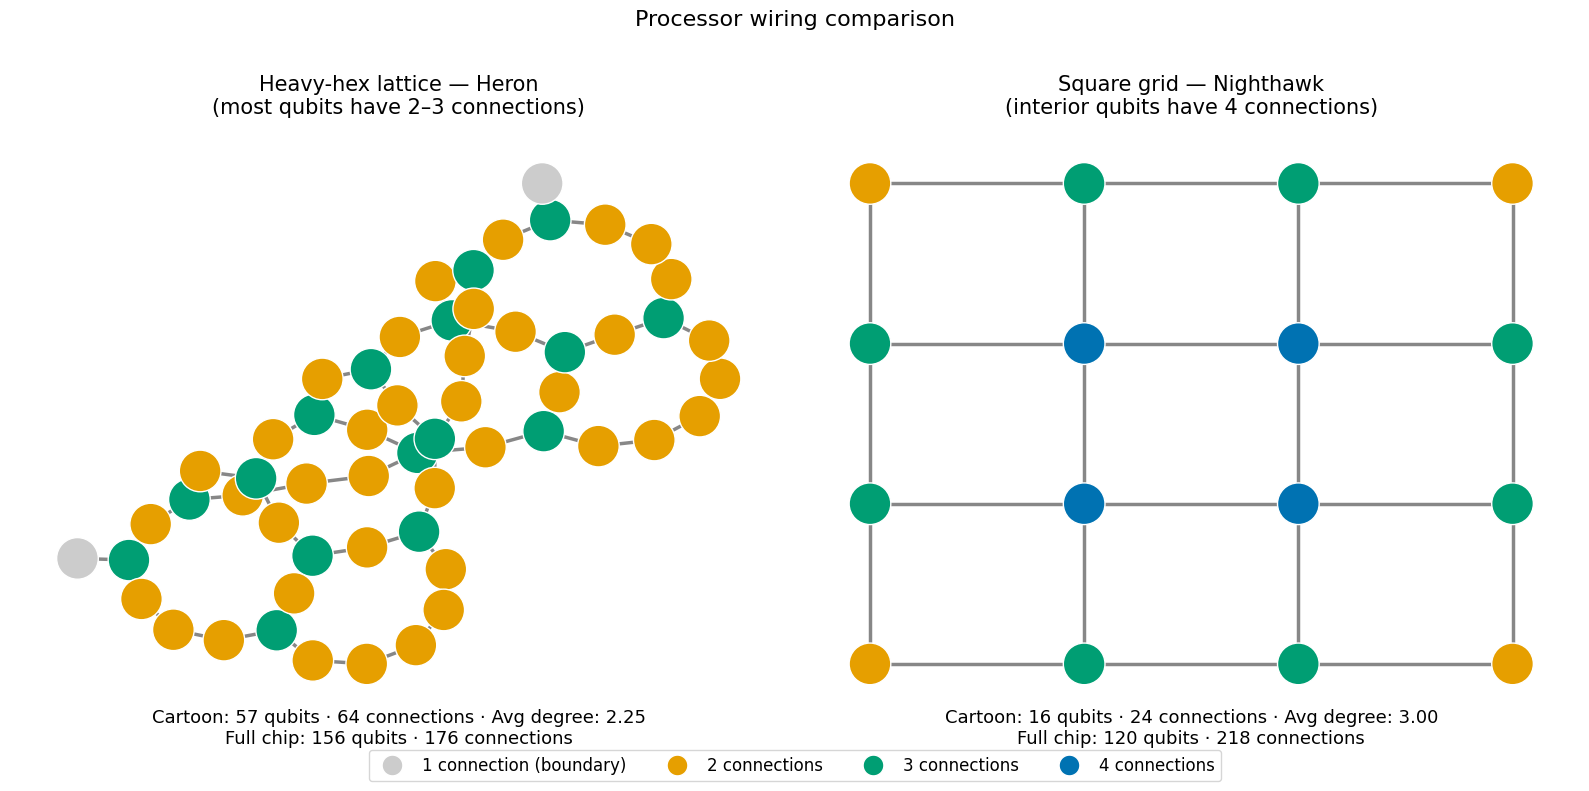

In [4]:
# ── Topology visualization ─────────────────────────────────
import networkx as nx
from matplotlib.lines import Line2D

# Build graphs
hh = CouplingMap.from_heavy_hex(5)
G_hh = nx.Graph(); G_hh.add_edges_from(hh.get_edges())

sq = CouplingMap.from_grid(4, 4)
G_sq = nx.Graph(); G_sq.add_edges_from(sq.get_edges())
pos_sq = {r*4 + c: (c, -r) for r in range(4) for c in range(4)}

try:
    pos_hh = nx.nx_agraph.graphviz_layout(G_hh, prog='neato')
except Exception:
    pos_hh = nx.kamada_kawai_layout(G_hh)

palette = {1: '#CCCCCC', 2: '#E69F00', 3: '#009E73', 4: '#0072B2'}

def degree_colors(G):
    return [palette[min(dict(G.degree())[n], 4)] for n in G.nodes()]

fig_l, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))

# LEFT: Heron (heavy-hex)
nx.draw_networkx_edges(G_hh, pos_hh, ax=ax1, edge_color='#555555',
                       width=2.5, alpha=0.7)
nx.draw_networkx_nodes(G_hh, pos_hh, ax=ax1, node_color=degree_colors(G_hh),
                       node_size=900, edgecolors='white', linewidths=1.0)
avg_hh = sum(d for _, d in G_hh.degree()) / len(G_hh)
ax1.set_title('Heavy-hex lattice — Heron\n(most qubits have 2–3 connections)',
              fontsize=15, pad=14)
ax1.text(0.5, -0.05,
         f'Cartoon: {len(G_hh)} qubits · {len(G_hh.edges())} connections · '
         f'Avg degree: {avg_hh:.2f}\n'
         f'Full chip: 156 qubits · 176 connections',
         transform=ax1.transAxes, ha='center', fontsize=13)
ax1.axis('off')

# RIGHT: Nighthawk (grid)
nx.draw_networkx_edges(G_sq, pos_sq, ax=ax2, edge_color='#555555',
                       width=2.5, alpha=0.7)
nx.draw_networkx_nodes(G_sq, pos_sq, ax=ax2, node_color=degree_colors(G_sq),
                       node_size=900, edgecolors='white', linewidths=1.0)
avg_sq = sum(d for _, d in G_sq.degree()) / len(G_sq)
ax2.set_title('Square grid — Nighthawk\n(interior qubits have 4 connections)',
              fontsize=15, pad=14)
ax2.text(0.5, -0.05,
         f'Cartoon: {len(G_sq)} qubits · {len(G_sq.edges())} connections · '
         f'Avg degree: {avg_sq:.2f}\n'
         f'Full chip: 120 qubits · 218 connections',
         transform=ax2.transAxes, ha='center', fontsize=13)
ax2.axis('off')

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[1],
           markersize=15, label='1 connection (boundary)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[2],
           markersize=15, label='2 connections'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[3],
           markersize=15, label='3 connections'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[4],
           markersize=15, label='4 connections'),
]
fig_l.legend(handles=legend_elements, loc='lower center', ncol=4,
             bbox_to_anchor=(0.5, -0.02), fontsize=12, frameon=True)
fig_l.suptitle('Processor wiring comparison', fontsize=16, y=1.02)
fig_l.tight_layout()
plt.subplots_adjust(bottom=0.08)
fig_l.savefig('lattice_comparison.jpg', dpi=250, bbox_inches='tight', facecolor='white')
print(f'Heavy-hex avg degree: {avg_hh:.2f}   Square grid avg degree: {avg_sq:.2f}')
fig_l;

## 5. Circuit construction

The function below builds the circuit from Fig. 1(b) of the paper. The
gate sequence was described in §1. We draw it at $N=3$ for readability;
the analysis sweeps up to $N=12$.

The two $X$ gates around the second controlled rotation flip the control:
the first controlled rotation fires when $Q = |1\rangle$ (filled dot in
the paper), and the second fires when $Q = |0\rangle$ (hollow dot). This
ensures the offset $\delta$ appears once in each schedule — before the
measurement train in $\mathcal{B}$ and after it in $\mathcal{A}$.

In [5]:
def build_zeno_clock(N, Omega_T=3.0, Omega_delta=math.pi/4):
    '''Build the superposed-schedule Zeno circuit (Fig. 1(b)).

    N            number of memory qubits
    Omega_T      normalized total drive interval (3.0 for Fig. 1(b))
    Omega_delta  schedule offset in units of 1/Omega
    '''
    Omega_dt = Omega_T / N
    S = QuantumRegister(1, name='S')
    Q = QuantumRegister(1, name='Q')
    M = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)

    qc.h(Q[0])                                # prepare Q in |+>_Q
    qc.crx(Omega_delta, Q[0], S[0])           # schedule-B start delay

    for i in range(N):                         # measurement train
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])

    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])           # schedule-A end delay (open ctl)
    qc.x(Q[0])

    qc.h(Q[0])                                # readout prep
    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc

N_demo = 3
qc_demo = build_zeno_clock(N_demo)
print(f'Zeno-clock circuit (N={N_demo}): {qc_demo.num_qubits} qubits, '
      f'abstract depth {qc_demo.depth()}')
print(f'Abstract gate counts: {dict(qc_demo.count_ops())}')

Zeno-clock circuit (N=3): 5 qubits, abstract depth 12
Abstract gate counts: {'measure': 5, 'rx': 3, 'cx': 3, 'h': 2, 'crx': 2, 'x': 2}


In [6]:
# ── Draw circuit with bracket annotations ──────────────────
# Use barriers to prevent Qiskit from reordering gates across sections

def build_zeno_clock_barriers(N, Omega_T=3.0, Omega_delta=math.pi/4):
    Omega_dt = Omega_T / N
    S = QuantumRegister(1, name='S')
    Q = QuantumRegister(1, name='Q')
    M = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)
    qc.h(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.barrier()
    for i in range(N):
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])
    qc.barrier()
    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.x(Q[0])
    qc.barrier()
    qc.h(Q[0])
    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc

qc_draw = build_zeno_clock_barriers(N_demo)
fig_zeno = qc_draw.draw(output='mpl', style='iqp', fold=-1)
ax_zeno = fig_zeno.axes[0]

# Colors matching the primitives
color_cr = '#D55E00'   # vermillion for CR_x
color_dr = '#009E73'   # green for drive+record

bracket_y = 0.75
label_y   = 1.15

# First CR_x bracket
ax_zeno.plot([0.4, 1.3], [bracket_y, bracket_y], color=color_cr, lw=2.5)
ax_zeno.plot([0.4, 0.4], [bracket_y, bracket_y - 0.15], color=color_cr, lw=2.5)
ax_zeno.plot([1.3, 1.3], [bracket_y, bracket_y - 0.15], color=color_cr, lw=2.5)
ax_zeno.text(0.85, label_y, '$CR_x$: 2 CX', ha='center', fontsize=11,
             color=color_cr, fontweight='bold')

# Drive+record brackets (N_demo of them)
for x_start in [2.4, 4.4, 6.4]:
    x_end = x_start + 1.9
    ax_zeno.plot([x_start, x_end], [bracket_y, bracket_y], color=color_dr, lw=2.5)
    ax_zeno.plot([x_start, x_start], [bracket_y, bracket_y - 0.15], color=color_dr, lw=2.5)
    ax_zeno.plot([x_end, x_end], [bracket_y, bracket_y - 0.15], color=color_dr, lw=2.5)

ax_zeno.text(4.85, label_y, f'Drive + record (×{N_demo}): 1 CX each',
             ha='center', fontsize=11, color=color_dr, fontweight='bold')

# Second CR_x bracket
ax_zeno.plot([9.4, 12.3], [bracket_y, bracket_y], color=color_cr, lw=2.5)
ax_zeno.plot([9.4, 9.4], [bracket_y, bracket_y - 0.15], color=color_cr, lw=2.5)
ax_zeno.plot([12.3, 12.3], [bracket_y, bracket_y - 0.15], color=color_cr, lw=2.5)
ax_zeno.text(10.85, label_y, '$CR_x$: 2 CX', ha='center', fontsize=11,
             color=color_cr, fontweight='bold')

# Total
ax_zeno.text(6.5, 1.75,
             f'Total: 2×2 + {N_demo}×1 = {N_demo + 4} CX gates',
             ha='center', fontsize=13, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#f0f0f0',
                       edgecolor='#999999', alpha=0.9))

ax_zeno.set_ylim(ax_zeno.get_ylim()[0], 2.2)
fig_zeno.suptitle(f'Zeno-clock circuit (N={N_demo})', fontsize=14, y=0.98)
fig_zeno.savefig('zeno_panel_b.jpg', dpi=200, bbox_inches='tight', facecolor='white')
fig_zeno;

## 6. Two-qubit gate primitives

The circuit has two kinds of two-qubit interaction: the controlled
rotation $CR_x$ (appears twice) and the drive-and-record step — a
rotation $R_x(\Omega\Delta t)$ on $S$ followed by a CX gate from $S$ to a
memory (appears $N$ times).

Neither of these is a gate that the IBM hardware can run directly. The
hardware can only run a basic set of gates (CX, RZ, SX, X). So each
operation must be broken down into those basic gates. The cell below
finds out how many CX gates each one costs.

In [7]:
basis = ['cx', 'rz', 'sx', 'x', 'measure']
cmap_pair = CouplingMap([[0, 1], [1, 0]])

# Primitive 1: controlled-R_x on a native 2-qubit pair
qc_cr = QuantumCircuit(2)
qc_cr.crx(math.pi/4, 0, 1)
tqc_cr = transpile(qc_cr, basis_gates=basis, coupling_map=cmap_pair,
                   optimization_level=1, seed_transpiler=42)
cr_cx    = tqc_cr.count_ops().get('cx', 0)
cr_depth = tqc_cr.depth(lambda g: len(g.qubits) == 2)
print(f'Controlled-R_x primitive: {cr_cx} CX gates, 2q-depth {cr_depth}')

# Primitive 2: drive + record block (R_x on S, then CX S -> M)
qc_rec = QuantumCircuit(2)
qc_rec.rx(0.4, 0)
qc_rec.cx(0, 1)
tqc_rec = transpile(qc_rec, basis_gates=basis, coupling_map=cmap_pair,
                    optimization_level=1, seed_transpiler=42)
rec_cx    = tqc_rec.count_ops().get('cx', 0)
rec_depth = tqc_rec.depth(lambda g: len(g.qubits) == 2)
print(f'Drive + record primitive:   {rec_cx} CX gate,  2q-depth {rec_depth}')

fig_cr  = tqc_cr.draw(output='mpl', style='iqp', fold=-1)
fig_cr.savefig('zeno_panel_a.jpg', dpi=200, bbox_inches='tight', facecolor='white')
plt.close(fig_cr)
fig_rec = tqc_rec.draw(output='mpl', style='iqp', fold=-1)
fig_rec.savefig('zeno_panel_a2.jpg', dpi=200, bbox_inches='tight', facecolor='white')
plt.close(fig_rec)

Controlled-R_x primitive: 2 CX gates, 2q-depth 2
Drive + record primitive:   1 CX gate,  2q-depth 1


## 7. Ideal cost (no extra wiring gates)

If every qubit that needs to interact with $S$ could sit physically next
to it on the chip, no extra gates would be needed to shuffle qubits
around. The ideal cost is:

- 2 controlled rotations × 2 CX gates each = 4 CX gates
- $N$ drive-and-record steps × 1 CX gate each = $N$ CX gates
- **Total: $N + 4$ CX gates**

Every two-qubit gate involves $S$, so they all run one after another.
The two-qubit depth equals the CX count: $N + 4$. This is a lower
bound; any real chip will add overhead because not all qubits can be
adjacent to $S$ at once.

In [8]:
Ns = [2, 4, 6, 8, 10, 12]
ideal_cx    = [N * rec_cx    + 2 * cr_cx    for N in Ns]
ideal_depth = [N * rec_depth + 2 * cr_depth for N in Ns]

print(f'{"N":>3} | {"CX gates (ideal)":>17} | {"2q-depth (ideal)":>17}')
print('-' * 44)
for N, c, d in zip(Ns, ideal_cx, ideal_depth):
    print(f'{N:>3} | {c:>17} | {d:>17}')

  N |  CX gates (ideal) |  2q-depth (ideal)
--------------------------------------------
  2 |                 6 |                 6
  4 |                 8 |                 8
  6 |                10 |                10
  8 |                12 |                12
 10 |                14 |                14
 12 |                16 |                16


## 8. Compilation at optimization level 0

We compile at `optimization_level=0`. At this level, Qiskit maps every
gate to the hardware's basic gate set and inserts SWAP gates wherever
qubits that need to interact are not physically connected, but does not
try to rearrange qubits or simplify the result.

This gives an upper bound on the gate count. A real hardware run would
typically use `opt=2`, which tries different qubit placements to reduce
the number of SWAPs needed. We use `opt=0` here because every gate in
the input maps transparently to the output, so the compiled circuit is
easy to check against the paper.

In [9]:
def transpile_best(qc, cmap, basis, opt_level):
    '''Transpile the circuit onto the given coupling map.'''
    return transpile(qc, coupling_map=cmap, basis_gates=basis,
                     optimization_level=opt_level, seed_transpiler=19)


def run_sweep(opt_level, Ns=Ns, verbose=True):
    '''Transpile the Zeno circuit at every N on both topologies.'''
    cmap_nh = CouplingMap.from_grid(5, 5)
    cmap_hr = CouplingMap.from_heavy_hex(7)

    out = {'opt_level': opt_level, 'Ns': list(Ns),
           'nh_cx': [], 'nh_depth': [], 'hr_cx': [], 'hr_depth': []}
    for N in Ns:
        qc = build_zeno_clock(N)
        tqc_nh = transpile_best(qc, cmap_nh, basis, opt_level=opt_level)
        tqc_hr = transpile_best(qc, cmap_hr, basis, opt_level=opt_level)
        out['nh_cx'].append(tqc_nh.count_ops().get('cx', 0))
        out['nh_depth'].append(tqc_nh.depth(lambda g: len(g.qubits) == 2))
        out['hr_cx'].append(tqc_hr.count_ops().get('cx', 0))
        out['hr_depth'].append(tqc_hr.depth(lambda g: len(g.qubits) == 2))

    if verbose:
        print(f'Sweep at optimization_level = {opt_level}')
        print()
        print(f'{"N":>3} | {"ideal CX":>12} | {"NH CX":>10} | {"HR CX":>10} || '
              f'{"ideal 2q-depth":>15} | {"NH 2q-depth":>12} | {"HR 2q-depth":>12}')
        print('-' * 100)
        for N, ic, nc, hc, id_, nd, hd in zip(out['Ns'], ideal_cx, out['nh_cx'], out['hr_cx'],
                                              ideal_depth, out['nh_depth'], out['hr_depth']):
            print(f'{N:>3} | {ic:>12} | {nc:>10} | {hc:>10} || {id_:>15} | {nd:>12} | {hd:>12}')
    return out

## 9. Fidelity budget

Two things eat into the circuit fidelity as $N$ grows:

$$\boxed{F \;\approx\; (1 - \varepsilon)^{D} \;\cdot\; \exp\Bigl(-\frac{D\,t_{\text{CZ}}}{T_2^*}\Bigr)}$$

**1. Gate errors.**  Each two-qubit gate has error rate $\varepsilon$.
After compilation, the circuit uses $D$ two-qubit gates. Each one
independently contributes some probability of error, giving the first
factor.

**2. Decoherence.**  The circuit is fully sequential on $S$ — every
two-qubit gate involves $S$, so the circuit duration is $D \times
t_{\text{CZ}}$. During this time, all qubits gradually lose their quantum
coherence. We use $T_2^*$ (the Ramsey dephasing time), not $T_2$ (the
echo dephasing time), because no correcting pulses act on any qubit
during the gate sequence. This makes $T_2^*$ the correct dephasing
rate to use.

### Why $T_2^*$, not $T_2$?

IBM's calibration reports $T_2$ from an echo experiment (~167 μs for
Heron, ~200 μs for Nighthawk). The echo experiment applies a
correcting pulse that cancels low-frequency noise, extending the
apparent coherence time.

No such pulse appears in the Zeno circuit. Qubits sit idle between
their gate operations with nothing to correct for drifts. They dephase
at the Ramsey rate $T_2^*$, which is about 5–6× shorter than $T_2$.
This is not a conservative assumption — it is the physically correct
dephasing rate for this circuit.

Agrawal et al. ([arXiv:2603.03157](https://arxiv.org/abs/2603.03157))
measured $T_2^*$ on the previous-generation Eagle processors:

| Device | $T_2$ echo (IBM cal.) | $T_2^*$ Ramsey (measured) |
|---|---|---|
| ibm_sherbrooke qubit 40 | 327 μs | 52 μs |
| ibm_brisbane qubit 118 | 126 μs | 34 μs |

We adopt $T_2^* \approx 50\;\mu$s for both chips. This is a
conservative estimate based on Eagle-generation hardware; the true
value on Heron and Nighthawk may be different, but direct measurements
are not publicly available. Using $T_2$ here would overestimate the coherence time by a factor
of 5–6× and give a misleadingly optimistic fidelity. Using $T_2^*$
measured on an older processor generation is conservative in the
opposite direction — current hardware may do better.

### Worked example (Nighthawk, $\varepsilon = 3.1 \times 10^{-3}$, $T_2^* = 50\;\mu$s)

**At $N = 8$, `opt=0`** the compiler gives $D = 48$ CX gates on Nighthawk.
The circuit takes $48 \times 68$ ns $= 3.26\;\mu$s.

$$F \approx (1 - 0.0031)^{48} \cdot \exp\left(-\frac{48 \times 68}{50{,}000}\right)
    = 0.862 \times 0.937 = 0.808$$

Gate error costs ~14%; decoherence costs ~6%. Plenty of headroom.

**At $N = 8$ on Heron** the compiler gives $D = 108$ CX gates.
The circuit takes $108 \times 68$ ns $= 7.34\;\mu$s.

$$F \approx (1 - 0.0043)^{108} \cdot \exp\left(-\frac{108 \times 68}{50{,}000}\right)
    = 0.628 \times 0.863 = 0.542$$

Gate error costs ~37%; decoherence costs ~14%. Close to the limit.

### Reading the fidelity plot

As fidelity drops, the predicted signal separation of ~0.30 (at $N=8$,
$\Omega\delta = \pi/2$) shrinks proportionally, and more shots are
needed to resolve it. We plot $F$ versus $N$ below, using the
actual compiled CX count at `opt=0`. The annotation next to each point
shows the CX count $D$.

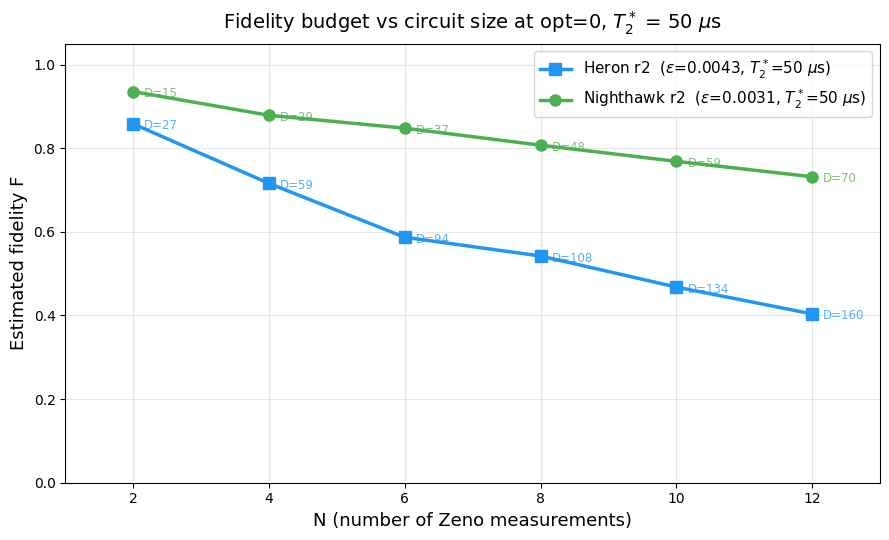

In [10]:
# -- Fidelity budget vs N (memory qubits) ---------------------------
# We plot F(N) for each chip, using the actual compiled CX count
# from opt=0 transpilation rather than a generic D range.

Ns_fb = [2, 4, 6, 8, 10, 12]

fig_fb, ax = plt.subplots(figsize=(9, 5.5))

for hw, cmap, color, marker in [
    (HERON, CouplingMap.from_heavy_hex(7), '#2196F3', 's'),
    (NIGHTHAWK, CouplingMap.from_grid(5, 5), '#4CAF50', 'o'),
]:
    basis_fb = ['cx', 'rz', 'sx', 'x', 'measure']
    T2star_ns = hw.T2_star_us * 1000
    Fs = []
    Ds = []
    for N in Ns_fb:
        qc = build_zeno_clock(N)
        tqc = transpile_best(qc, cmap, basis_fb, opt_level=0)
        D = tqc.count_ops().get('cx', 0)
        F = (1 - hw.cz_err)**D * np.exp(-D * hw.cz_ns / T2star_ns)
        Fs.append(F)
        Ds.append(D)
    ax.plot(Ns_fb, Fs, '-', color=color, lw=2.5, marker=marker, markersize=8,
            label=f'{hw.name}  ($\\varepsilon$={hw.cz_err}, $T_2^*$={hw.T2_star_us} $\\mu$s)')
    # Annotate D values next to each point
    for n, f, d in zip(Ns_fb, Fs, Ds):
        ax.annotate(f'D={d}', (n, f), textcoords='offset points',
                    xytext=(8, -4), fontsize=8.5, color=color, alpha=0.75)

ax.set_xlabel('N (number of Zeno measurements)', fontsize=13)
ax.set_ylabel('Estimated fidelity F', fontsize=13)
ax.set_title('Fidelity budget vs circuit size at opt=0, $T_2^*$ = 50 $\\mu$s',
             fontsize=14, pad=10)
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xticks(Ns_fb)
ax.set_xlim(1, 13)
ax.set_ylim(0, 1.05)
fig_fb.tight_layout()
fig_fb.savefig('zeno_fidelity_budget.jpg', dpi=250, bbox_inches='tight', facecolor='white')
fig_fb;

In [11]:
def make_composite_figure(results, filename, circuit_img='zeno_panel_b.jpg', circuit_label=None):
    '''Build the 4-panel composite figure.'''
    opt_level = results['opt_level']
    Ns_       = results['Ns']
    nh_cx     = results['nh_cx']
    nh_depth  = results['nh_depth']
    hr_cx     = results['hr_cx']
    hr_depth  = results['hr_depth']

    img_cr   = mpimg.imread('zeno_panel_a.jpg')
    img_rec  = mpimg.imread('zeno_panel_a2.jpg')
    img_full = mpimg.imread(circuit_img)

    color_nh = '#0072B2'; color_hr = '#E69F00'; color_id = '#666666'
    TITLE_FS = 19; SUBTITLE_FS = 14; LABEL_FS = 18; TICK_FS = 15; LEGEND_FS = 14

    if circuit_label is None:
        circuit_label = (f'(b) Full Zeno-clock circuit (N={N_demo}):\n'
                         f'2 controlled-$R_x$ boxes + {N_demo} drive+record pairs')

    fig = plt.figure(figsize=(16, 13))
    gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1, 1.05],
                           height_ratios=[1, 1], wspace=0.22, hspace=0.32)

    # Top-left: two-qubit gate primitives
    ax_a_outer = fig.add_subplot(gs[0, 0]); ax_a_outer.axis('off')
    ax_a_outer.set_title('(a) Two-qubit gate primitives on native pair',
                         fontsize=TITLE_FS, loc='center', pad=8)
    gs_a = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[0, 0],
                                            height_ratios=[1, 1], hspace=0.45)
    ax_a1 = fig.add_subplot(gs_a[0]); ax_a1.imshow(img_cr); ax_a1.axis('off')
    ax_a1.set_title(f'Controlled-$R_x$: {cr_cx} CX gates, 2q-depth {cr_depth}',
                    fontsize=SUBTITLE_FS, loc='center', pad=4)
    ax_a2 = fig.add_subplot(gs_a[1]); ax_a2.imshow(img_rec); ax_a2.axis('off')
    ax_a2.set_title(f'Drive + record: {rec_cx} CX gate, 2q-depth {rec_depth}',
                    fontsize=SUBTITLE_FS, loc='center', pad=4)

    # Bottom-left: full circuit
    ax_b = fig.add_subplot(gs[1, 0]); ax_b.imshow(img_full); ax_b.axis('off')
    ax_b.set_title(circuit_label, fontsize=TITLE_FS, loc='center', pad=10)

    gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[:, 1],
                                            height_ratios=[1, 1], hspace=0.32)

    # Panel (c): depth vs N
    ax_c = fig.add_subplot(gs_r[0])
    ax_c.plot(Ns_, nh_depth,   'o-',  color=color_nh, linewidth=3.5, markersize=14, label='Nighthawk')
    ax_c.plot(Ns_, hr_depth,   's--', color=color_hr, linewidth=3.5, markersize=14, label='Heron')
    ax_c.plot(Ns_, ideal_depth,'^:',  color=color_id, linewidth=2.5, markersize=12, label='Ideal (no routing)')

    ax_c.set_xlabel('N (memory qubits)', fontsize=LABEL_FS, labelpad=8)
    ax_c.set_ylabel('2-qubit gate depth', fontsize=LABEL_FS, labelpad=8)
    ax_c.set_title(f'(c) 2-qubit depth vs N  [opt={opt_level}]', fontsize=TITLE_FS, pad=12)
    ax_c.tick_params(axis='both', labelsize=TICK_FS)
    ax_c.legend(fontsize=LEGEND_FS - 2, loc='upper left', frameon=True)
    ax_c.grid(True, alpha=0.3); ax_c.set_xticks(Ns_)
    ax_c.set_ylim(0, max(hr_depth) * 1.1)

    # Panel (d): CX count vs N
    ax_d = fig.add_subplot(gs_r[1])
    ax_d.plot(Ns_, nh_cx,   'o-',  color=color_nh, linewidth=3.5, markersize=14, label='Nighthawk')
    ax_d.plot(Ns_, hr_cx,   's--', color=color_hr, linewidth=3.5, markersize=14, label='Heron')
    ax_d.plot(Ns_, ideal_cx,'^:',  color=color_id, linewidth=2.5, markersize=12, label='Ideal (no routing)')
    ax_d.set_xlabel('N (memory qubits)', fontsize=LABEL_FS, labelpad=8)
    ax_d.set_ylabel('CX count', fontsize=LABEL_FS, labelpad=8)
    ax_d.set_title(f'(d) CX count vs N  [opt={opt_level}]', fontsize=TITLE_FS, pad=12)
    ax_d.tick_params(axis='both', labelsize=TICK_FS)
    ax_d.legend(fontsize=LEGEND_FS, loc='upper left', frameon=True)
    ax_d.grid(True, alpha=0.3); ax_d.set_xticks(Ns_)

    fig.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'Saved {filename} at 300 DPI')
    return fig

---

## 10. Experiment 1: Conditional system probabilities

The first test measures $P_0^{(N,+)}$ and $P_0^{(N,-)}$. The paper
predicts $P_0^{(N,-)} = 1 - P_0^{(N)}$, independent of $\delta$.

The sweep below compiles the circuit at each $N$ onto both chips at
`opt=0` and records the CX count and two-qubit depth.

In [12]:
results_opt0 = run_sweep(opt_level=0)

Sweep at optimization_level = 0

  N |     ideal CX |      NH CX |      HR CX ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |         15 |         27 ||               6 |           15 |           24
  4 |            8 |         29 |         59 ||               8 |           26 |           35
  6 |           10 |         37 |         94 ||              10 |           32 |           49
  8 |           12 |         48 |        108 ||              12 |           39 |           66
 10 |           14 |         59 |        134 ||              14 |           49 |           89
 12 |           16 |         70 |        160 ||              16 |           55 |          115


Saved zeno_feasibility_opt0.jpg at 300 DPI


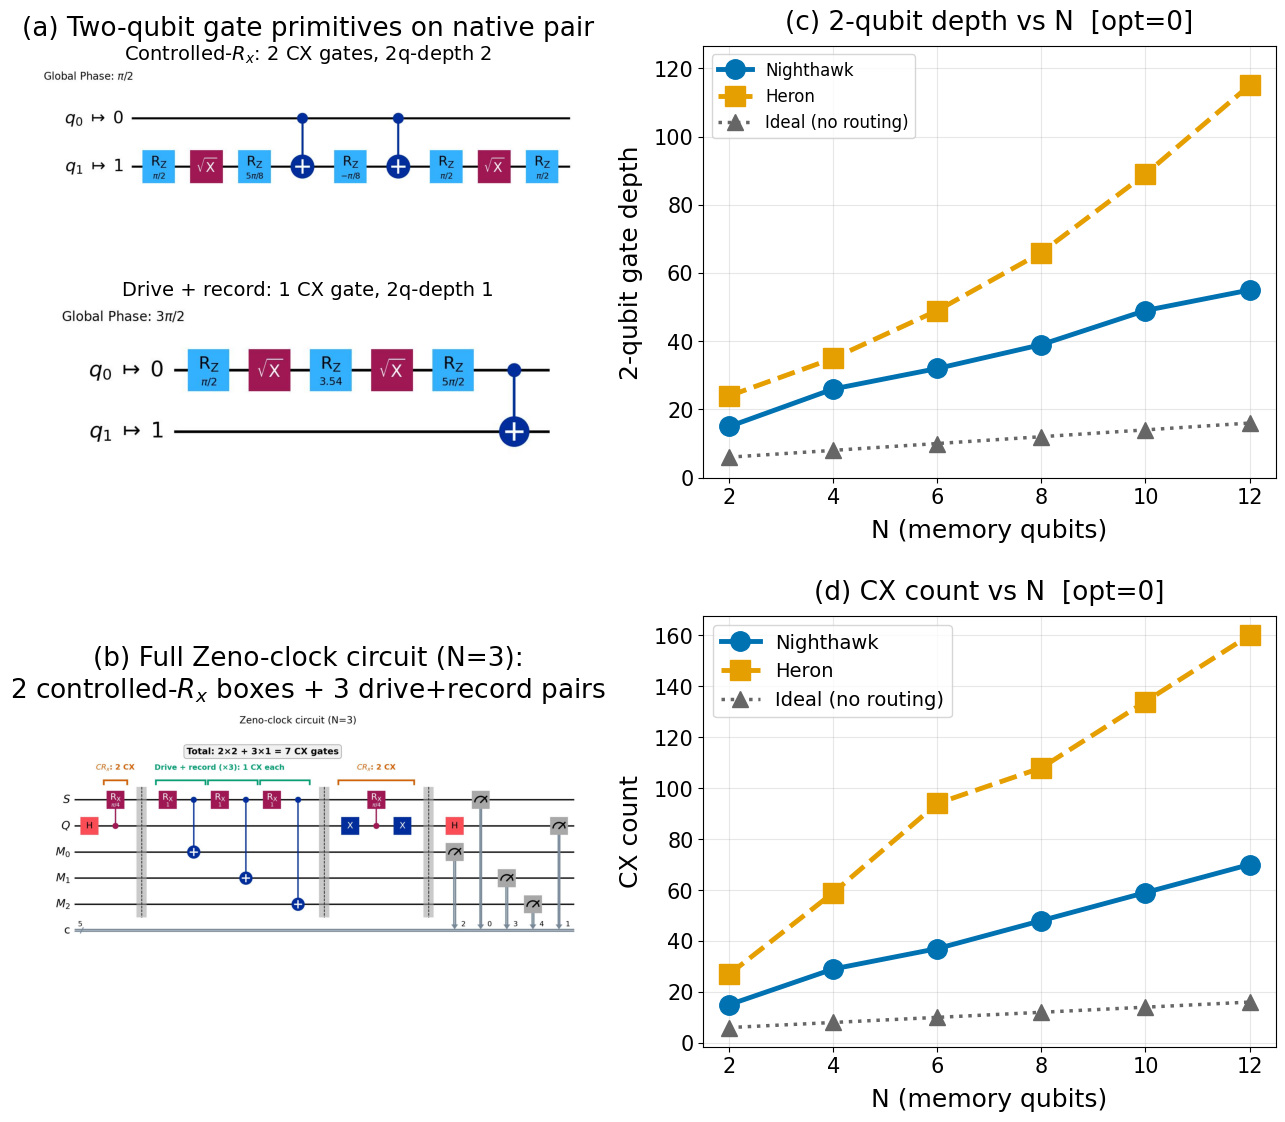

In [13]:
fig_opt0 = make_composite_figure(results_opt0, filename='zeno_feasibility_opt0.jpg')

### Observations

Nighthawk stays at high fidelity through the full sweep. Heron's
compiled depth grows much faster because its sparser wiring requires
more SWAP gates, and by moderate $N$ the accumulated gate error becomes
significant.

Nighthawk's advantage comes from connectivity: a qubit with 4 neighbors
can hold more of $S$'s partners adjacent, so fewer SWAPs are needed.

---

## 11. Experiment 2: Memory parity

The second test measures the joint $X$-basis parity of the memory
register: multiply the $\pm 1$ measurement outcomes of all $N$ memories
measured in the $X$ basis. Conditioned on the $|-\rangle_Q$ outcome, the
ideal product is exactly $-1$ for any $N$. A classical or dephased
schedule gives zero.

The circuit differs from Experiment 1 by one line: a Hadamard gate on
each memory before readout, which rotates the $X$-basis measurement into
the standard ($Z$) basis that the hardware measures. The two-qubit
structure is unchanged, so the CX counts and depths match Experiment 1
exactly.

In [14]:
def build_zeno_clock_xbasis(N, Omega_T=3.0, Omega_delta=math.pi/4):
    '''Experiment 2 variant: Hadamards on memories before readout.'''
    Omega_dt = Omega_T / N
    S  = QuantumRegister(1, name='S')
    Q  = QuantumRegister(1, name='Q')
    M  = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)

    qc.h(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])

    for i in range(N):
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])

    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.x(Q[0])
    qc.h(Q[0])

    for i in range(N):               # the only change vs Experiment 1
        qc.h(M[i])                   # rotate X-parity into Z-parity

    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc


def run_sweep_xbasis(opt_level, Ns=Ns, verbose=True):
    '''Same as run_sweep but for the X-basis-readout circuit.'''
    cmap_nh = CouplingMap.from_grid(5, 5)
    cmap_hr = CouplingMap.from_heavy_hex(7)
    out = {'opt_level': opt_level, 'Ns': list(Ns),
           'nh_cx': [], 'nh_depth': [], 'hr_cx': [], 'hr_depth': []}
    for N in Ns:
        qc = build_zeno_clock_xbasis(N)
        tqc_nh = transpile_best(qc, cmap_nh, basis, opt_level=opt_level)
        tqc_hr = transpile_best(qc, cmap_hr, basis, opt_level=opt_level)
        out['nh_cx'].append(tqc_nh.count_ops().get('cx', 0))
        out['nh_depth'].append(tqc_nh.depth(lambda g: len(g.qubits) == 2))
        out['hr_cx'].append(tqc_hr.count_ops().get('cx', 0))
        out['hr_depth'].append(tqc_hr.depth(lambda g: len(g.qubits) == 2))

    if verbose:
        print(f'X-basis sweep at optimization_level = {opt_level}')
        print()
        print(f'{"N":>3} | {"ideal CX":>12} | {"NH CX":>10} | {"HR CX":>10} || '
              f'{"ideal 2q-depth":>15} | {"NH 2q-depth":>12} | {"HR 2q-depth":>12}')
        print('-' * 100)
        for N, ic, nc, hc, id_, nd, hd in zip(out['Ns'], ideal_cx, out['nh_cx'], out['hr_cx'],
                                              ideal_depth, out['nh_depth'], out['hr_depth']):
            print(f'{N:>3} | {ic:>12} | {nc:>10} | {hc:>10} || {id_:>15} | {nd:>12} | {hd:>12}')
    return out


results_opt0_xb = run_sweep_xbasis(opt_level=0)

X-basis sweep at optimization_level = 0

  N |     ideal CX |      NH CX |      HR CX ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |         15 |         27 ||               6 |           15 |           24
  4 |            8 |         29 |         59 ||               8 |           26 |           35
  6 |           10 |         37 |         94 ||              10 |           32 |           49
  8 |           12 |         48 |        108 ||              12 |           39 |           66
 10 |           14 |         59 |        134 ||              14 |           49 |           89
 12 |           16 |         70 |        160 ||              16 |           55 |          115


In [15]:
# ── Draw Experiment 2 circuit (X-basis readout) ────────────
# Same structure as the Experiment 1 circuit, plus a Hadamard
# on each memory before readout.

def build_zeno_clock_xbasis_barriers(N, Omega_T=3.0, Omega_delta=math.pi/4):
    '''Experiment 2 circuit with barriers for clean drawing.'''
    Omega_dt = Omega_T / N
    S = QuantumRegister(1, name='S')
    Q = QuantumRegister(1, name='Q')
    M = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)
    qc.h(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.barrier()
    for i in range(N):
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])
    qc.barrier()
    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.x(Q[0])
    qc.barrier()
    qc.h(Q[0])
    for i in range(N):
        qc.h(M[i])                   # X-basis rotation on each memory
    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc

qc_xb_draw = build_zeno_clock_xbasis_barriers(N_demo)
fig_xb = qc_xb_draw.draw(output='mpl', style='iqp', fold=-1)
fig_xb.suptitle(f'Experiment 2 circuit (N={N_demo}): X-basis readout on memories',
                fontsize=14, y=0.98)
fig_xb.savefig('zeno_panel_b_xbasis.jpg', dpi=200, bbox_inches='tight', facecolor='white')
fig_xb;

Saved zeno_feasibility_xbasis_opt0.jpg at 300 DPI


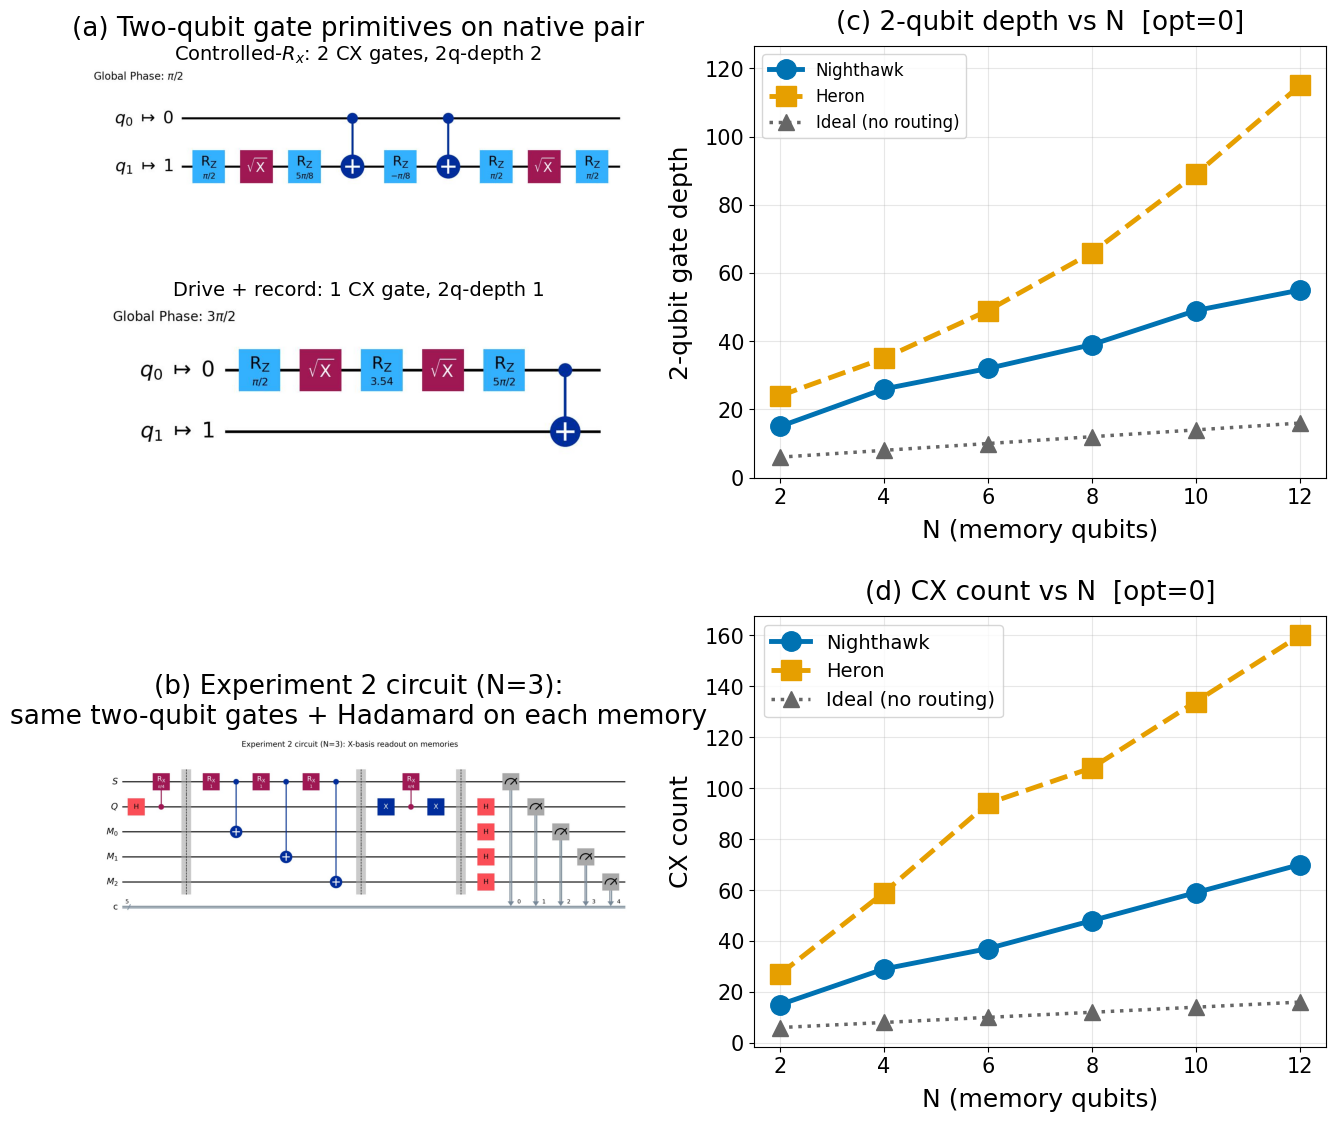

In [16]:
fig_opt0_xb = make_composite_figure(
    results_opt0_xb,
    filename='zeno_feasibility_xbasis_opt0.jpg',
    circuit_img='zeno_panel_b_xbasis.jpg',
    circuit_label=(f'(b) Experiment 2 circuit (N={N_demo}):\n'
                   f'same two-qubit gates + Hadamard on each memory'),
)

### Observations (Experiment 2)

The CX counts and depths are identical to Experiment 1, as expected.
The added Hadamards are single-qubit gates that do not affect the
two-qubit gate count.

The fidelity reference lines place Experiment 2 in the same position as
Experiment 1 for gate error. However, the parity signal has two
additional sources of error not shown here: readout error (each qubit
read incorrectly flips the parity) and memory dephasing (each memory
loses coherence while waiting to be read). These make the parity test
harder than the conditional-probability test at the same $N$. Small $N$
is the natural regime for Experiment 2.

## 12. A note on optimization levels

Before running a circuit on real hardware, Qiskit's compiler converts
it from abstract gates into the chip's basic gate set and maps it onto
physical qubits. The compiler has four optimization levels, which control
how hard it tries to reduce the gate count:

| Level | What it does |
|-------|-------------|
| 0 | No optimization. Uses the qubits you specify. |
| 1 | Tries a few different qubit placements, picks the one needing fewest SWAPs. |
| 2 | More thorough search over qubit placements. |
| 3 | Most thorough search. |

*For details, see the
[Qiskit transpiler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/transpiler#transpiler-preset-stage-optimization).*

For the Zeno circuit, Level 0 is a fine starting point. The
compiler cannot reduce the $N + 4$ two-qubit gates that the circuit
actually needs — those are the physics. Higher optimization levels can
only reduce the extra SWAP gates introduced by the chip's wiring, and
may cancel some redundant single-qubit gates. Since two-qubit gate error
is the dominant noise source, and the minimum two-qubit count is fixed
by the circuit, the benefit of higher levels is modest.

The cell below shows all four levels at $N=8$ on Nighthawk.

In [17]:
cmap_nh_cmp = CouplingMap.from_grid(5, 5)
N_cmp = 8
qc_cmp = build_zeno_clock(N_cmp)

print(f'Zeno circuit at N={N_cmp} on Nighthawk:')
print(f'{"opt level":>10} | {"CX gates":>10} | {"2q-depth":>10} | {"total gates":>12}')
print('-' * 50)
for opt in range(4):
    tqc = transpile_best(qc_cmp, cmap_nh_cmp, basis, opt_level=opt)
    cx = tqc.count_ops().get('cx', 0)
    d2 = tqc.depth(lambda g: len(g.qubits) == 2)
    total = sum(v for k, v in tqc.count_ops().items() if k != 'measure')
    print(f'{opt:>10} | {cx:>10} | {d2:>10} | {total:>12}')

Zeno circuit at N=8 on Nighthawk:
 opt level |   CX gates |   2q-depth |  total gates
--------------------------------------------------
         0 |         48 |         39 |          112
         1 |         24 |         24 |           80
         2 |         21 |         21 |           70
         3 |         18 |         18 |           66


## 13. Caveats

This notebook gives a simplified feasibility estimate. We do not model
readout error (~1–2% per qubit), $T_1$ relaxation of $S$ during the
circuit, per-qubit variation in gate fidelity, or the additional
dephasing of the memory qubits while they wait to be read (the paper
gives the exact formula for this effect). These could be added in a
future version to give a more accurate noise budget.